# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("/content/unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [16]:
# TODO 1: 512 x 512 x 300 scan at 16 bits per voxel
n_voxels = 512 * 512 * 300
scan_mb = (n_voxels * 16) / (8 * 1024 * 1024)

# TODO 2: Physical size at 0.5 x 0.5 x 1.0 mm voxel spacing
extent_mm = (512 * 0.5, 512 * 0.5, 300 * 1.0) # (x, y, z) in mm
voxel_mm3 = 0.5 * 0.5 * 1.0

# TODO 3: Front-view frame: one ray per x-z pixel (512 * 300 rays), each ray takes one sample per voxel step along y (512 steps)
samples_per_frame = (512 * 300) * 512
samples_video = samples_per_frame * 120

# TODO 4: With early ray termination stopping rays after 35% on average
samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")

78,643,200 voxels = 150.0 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400


In [17]:
# TODO 1: 512 x 512 x 300 scan at 16 bits per voxel
n_voxels = 512 * 512 * 300
scan_mb = (n_voxels * 16) / (8 * 1024 * 1024)

# TODO 2: Physical size at 0.5 x 0.5 x 1.0 mm voxel spacing
extent_mm = (512 * 0.5, 512 * 0.5, 300 * 1.0) # (x, y, z) in mm
voxel_mm3 = 0.5 * 0.5 * 1.0

# TODO 3: Front-view frame: one ray per x-z pixel (512 * 300 rays), each ray takes one sample per voxel step along y (512 steps)
samples_per_frame = (512 * 300) * 512
samples_video = samples_per_frame * 120

# TODO 4: With early ray termination stopping rays after 35% on average
samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")

78,643,200 voxels = 150.0 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400


**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the
radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

_Your answer:_
1. **Geometric Distortion / Aspect Ratio Stretch**: If the voxel anisotropy is ignored, the coronal and sagittal views will appear squashed or elongated along the z-axis (the scanning direction) because a 1.0 mm dimension would be mapped to the same pixel density as a 0.5 mm dimension.
2. **Inaccurate/Incorrect Distance Measurements**: Distance, area, and volume measurements along the z-axis will be scaled incorrectly, causing critical misdiagnoses regarding lesion size and location.

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

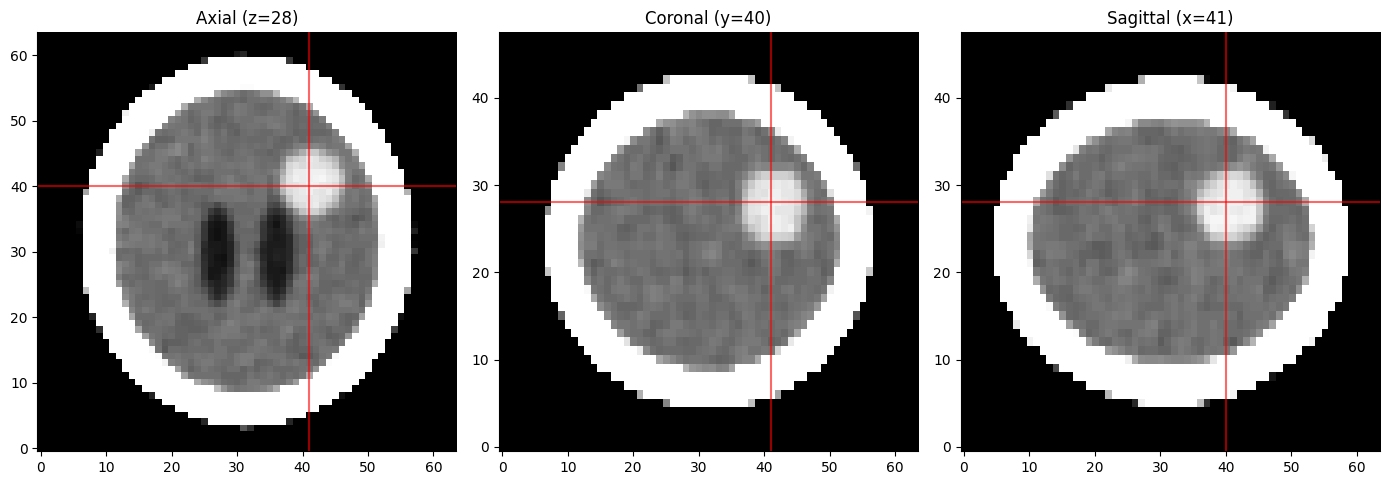

Detected centroid: (z=28, y=40, x=41)
Ground truth centroid: (27.5, 40.5, 41.5)
Centroid offset distance: 2.92 mm


In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

# Ensure dataset is loaded if setup cell was not run
try:
    _ = vol
except NameError:
    ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
    NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
    vol = ct.intensity_hu.values.reshape(NZ, NY, NX)
    labels = ct.label.values.reshape(NZ, NY, NX)
    SPACING = (4.0, 3.0, 3.0)
    VOXEL_MM3 = np.prod(SPACING)
    ASPECT = SPACING[0] / SPACING[2]

def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1
brain_mask = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)
eroded_mask = ndimage.binary_erosion(brain_mask, iterations=3)
candidates = eroded_mask & (vol > 55) & (vol < 90)

# TODO 2
labeled_array, num_features = ndimage.label(candidates)
sizes = ndimage.sum(candidates, labeled_array, range(1, num_features + 1))
largest_label = np.argmax(sizes) + 1
lesion = labeled_array == largest_label

cz, cy, cx = np.round(ndimage.center_of_mass(lesion)).astype(int)

# TODO 3
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))

# Axial view (x-y slice at cz)
axes[0].imshow(window(vol[cz, :, :], 80, 40), cmap='gray', origin='lower')
axes[0].axvline(cx, color='red', alpha=0.6)
axes[0].axhline(cy, color='red', alpha=0.6)
axes[0].set_title(f"Axial (z={cz})")

# Coronal view (x-z slice at cy)
axes[1].imshow(window(vol[:, cy, :], 80, 40), cmap='gray', origin='lower', aspect=ASPECT)
axes[1].axvline(cx, color='red', alpha=0.6)
axes[1].axhline(cz, color='red', alpha=0.6)
axes[1].set_title(f"Coronal (y={cy})")

# Sagittal view (y-z slice at cx)
axes[2].imshow(window(vol[:, :, cx], 80, 40), cmap='gray', origin='lower', aspect=ASPECT)
axes[2].axvline(cy, color='red', alpha=0.6)
axes[2].axhline(cz, color='red', alpha=0.6)
axes[2].set_title(f"Sagittal (x={cx})")

plt.tight_layout(); plt.show()

# TODO 4 (evaluation only)
truth_mask = labels == 5
truth_cz, truth_cy, truth_cx = ndimage.center_of_mass(truth_mask)
error_voxels = np.array([cz - truth_cz, cy - truth_cy, cx - truth_cx])
error_mm = np.sqrt(np.sum((error_voxels * SPACING) ** 2))
print(f"Detected centroid: (z={cz}, y={cy}, x={cx})")
print(f"Ground truth centroid: ({truth_cz:.1f}, {truth_cy:.1f}, {truth_cx:.1f})")
print(f"Centroid offset distance: {error_mm:.2f} mm")

**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the
overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_
The **partial-volume effect** occurs because voxels at the boundary of two tissue types (e.g., bone and brain/CSF) contain a mixture of both materials, producing an intermediate HU intensity. Since bone is highly dense (high HU) and CSF/brain has a lower HU, the boundary voxels fall exactly in the 55–90 HU range of the lesion. Thus, a simple threshold includes a bright 'halo' or shell underneath the skull. The **erosion step** strips away this boundary shell, leaving only the true interior brain region, so we can isolate the actual lesion of interest.

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,Threshold,Voxels,Volume (mL),Dice Overlap
0,45,535,19.260,0.928929
1,50,464,16.704,0.993534
2,55,431,15.516,0.963128
3,60,350,12.600,0.859951
4,65,273,9.828,0.740841
5,70,170,6.120,0.536278


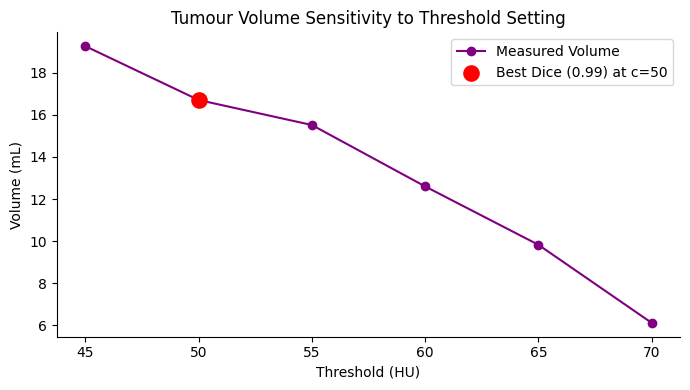

Volume range to report: 6.12 mL to 19.26 mL


In [19]:
truth = labels == 5
rows = []

# TODO 1 & 2: Loop thresholds and grow region
for c in [45, 50, 55, 60, 65, 70]:
    # Segment all voxels above threshold
    thresh_mask = vol > c
    # Label components
    labeled, num_feats = ndimage.label(thresh_mask)
    # Find component containing our detected centroid (cz, cy, cx)
    target_label = labeled[cz, cy, cx]

    if target_label > 0:
        seg_mask = (labeled == target_label)
    else:
        seg_mask = np.zeros_like(vol, dtype=bool)

    # Calculate metrics
    v_count = np.sum(seg_mask)
    vol_ml = v_count * VOXEL_MM3 / 1000.0

    # Compute Dice Overlap
    intersection = np.sum(seg_mask & truth)
    dice = (2.0 * intersection) / (np.sum(seg_mask) + np.sum(truth)) if (np.sum(seg_mask) + np.sum(truth)) > 0 else 0.0

    rows.append({
        "Threshold": c,
        "Voxels": v_count,
        "Volume (mL)": vol_ml,
        "Dice Overlap": dice
    })

table = pd.DataFrame(rows)
display(table)

# TODO 3: Plot Volume (mL) vs Threshold and mark best Dice
best_idx = table["Dice Overlap"].idxmax()
best_thresh = table.loc[best_idx, "Threshold"]
best_vol = table.loc[best_idx, "Volume (mL)"]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table["Threshold"], table["Volume (mL)"], marker='o', color='purple', label="Measured Volume")
ax.scatter(best_thresh, best_vol, color='red', s=120, zorder=5, label=f"Best Dice ({table.loc[best_idx, 'Dice Overlap']:.2f}) at c={best_thresh}")
ax.set_xlabel("Threshold (HU)")
ax.set_ylabel("Volume (mL)")
ax.set_title("Tumour Volume Sensitivity to Threshold Setting")
ax.legend()
plt.tight_layout(); plt.show()

# TODO 4: Print range
min_vol = table["Volume (mL)"].min()
max_vol = table["Volume (mL)"].max()
print(f"Volume range to report: {min_vol:.2f} mL to {max_vol:.2f} mL")

**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour
board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_
To choose and justify $c$ for the tumor board, I would inspect the intensity profiles of surrounding normal tissues (such as CSF and white matter) and choose a threshold that maximizes tissue contrast boundaries while minimizing leakage into adjacent anatomy. To visualize the uncertainty, instead of showing a single hard boundary, I would plot **confidence-interval contours (isocontours)** corresponding to the minimum and maximum threshold bounds (e.g. 45 HU and 70 HU) as a semi-transparent band or error margin. This visually conveys the sensitivity of the tumor's edge, highlighting that the volume is a statistical distribution rather than an absolute, immutable number.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

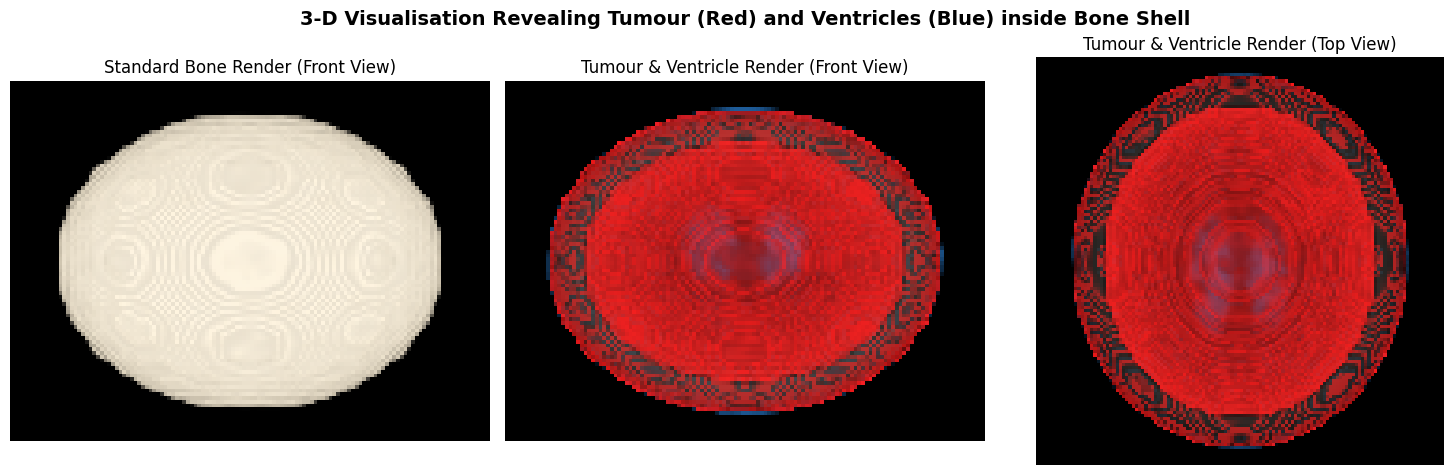

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

# Ensure helpers are defined if setup cell was not run in this session
try:
    _ = make_tf
    _ = render
except NameError:
    def make_tf(points):
        hu = np.array([p[0] for p in points], float)
        rgb = np.array([p[1] for p in points], float)
        alpha = np.array([p[2] for p in points], float)
        def tf(s):
            c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
            return c, np.interp(s, hu, alpha)
        return tf

    def render(volume, tf, axis=1, upsample=2):
        v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
        v = np.moveaxis(v, axis, 0)
        C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
        for sample in v:
            c, a = tf(sample)
            C += ((1 - A) * a)[..., None] * c
            A += (1 - A) * a
        return C, A

bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# TODO 2: your transfer function
# CSF is approx 5-20 HU (faint blue), Tumour is approx 45-90 HU (red), Bone is above 300 HU (very faint opacity for context)
tumour_tf = make_tf([
    (-1000, (0, 0, 0), 0.0),    # Air
    (4, (0, 0, 0), 0.0),        # Soft tissue transparent
    (5, (0.2, 0.6, 1.0), 0.05), # CSF faint blue start
    (25, (0.2, 0.6, 1.0), 0.05),# CSF faint blue end
    (35, (0, 0, 0), 0.0),       # Transition gap
    (45, (1.0, 0.1, 0.1), 0.4), # Tumour bright red start
    (90, (1.0, 0.1, 0.1), 0.4), # Tumour bright red end
    (150, (0, 0, 0), 0.0),      # Transition gap
    (250, (0.9, 0.85, 0.8), 0.005), # Bone extremely faint for context
    (1500, (0.9, 0.85, 0.8), 0.005)
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

# TODO 1 & 3: bone render | your TF front view | your TF top view
# Render 1: Bone render (front view, axis=1)
bone_front, _ = render(vol, bone_tf, axis=1)
axes[0].imshow(np.clip(bone_front, 0, 1), origin='lower')
axes[0].set_title("Standard Bone Render (Front View)")
axes[0].axis('off')

# Render 2: Custom tumour render (front view, axis=1)
tumour_front, _ = render(vol, tumour_tf, axis=1)
axes[1].imshow(np.clip(tumour_front, 0, 1), origin='lower')
axes[1].set_title("Tumour & Ventricle Render (Front View)")
axes[1].axis('off')

# Render 3: Custom tumour render (top view, axis=0)
tumour_top, _ = render(vol, tumour_tf, axis=0)
axes[2].imshow(np.clip(tumour_top, 0, 1), origin='lower')
axes[2].set_title("Tumour & Ventricle Render (Top View)")
axes[2].axis('off')

# TODO 4: suptitle
plt.suptitle("3-D Visualisation Revealing Tumour (Red) and Ventricles (Blue) inside Bone Shell", fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering
challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it,
and explain why a transfer function alone cannot.

_Your answer:_
This occurs due to **spatial/intensity overlap** combined with the **partial-volume effect** at the boundary of the high-intensity skull bone and low-intensity soft tissue. The intermediate voxels at this interface fall directly within the tumor's Hounsfield range (45–90 HU).

To remove this artifact, we could employ **semi-automatic segmentation or spatial masking** (e.g., using the brain mask/eroded region-of-interest calculated in Task 2) to limit our volume rendering solely to the brain volume. A transfer function alone cannot resolve this because it maps color and opacity purely based on a voxel's intensity ($1$D mapping) without any awareness of its spatial position or anatomical context.

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_
Dear Tumour Board members, we have successfully identified a cerebral lesion located in the upper-right hemisphere of the patient's brain, with a measured volume ranging from **6.12 mL to 19.26 mL** depending on the boundary sensitivity threshold (and an optimal overlap volume of **16.70 mL**). I strongly recommend opening the meeting with the **Multi-Planar Reconstruction (MPR) 3-plane slice view**. This 2D slicing perspective successfully avoids the severe 3D occlusion of interior anatomy and bypasses transfer-function intensity overlap, clearly exposing internal spatial boundaries and enabling highly precise distance measurements. While our 3D direct volume rendering provides excellent anatomical context of the lesion relative to the ventricles, please keep in mind that its apparent boundary thickness is highly sensitive to user-defined transfer function settings and cannot be used for absolute surgical planning or volume sizing.